# Task 2a plots: RRIP vs I-RRIP
Run the cells top to bottom. Figures are saved to `figures/` for the report.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

traces = ["Trace 1", "Trace 2", "Trace 3"]
BASELINE = "RRIP"

# Values from the ChampSim "Region of Interest" output.
# To add a variant (for the report's "Variants explored" table), add another key here.
data = {
    "RRIP": {
        "ipc":       [0.232007, 0.251127, 0.381616],
        "l2c_load":  [17.5872, 26.8715, 4.04704],
        "l2c_instr": [10.5207, 18.9032, 1.2016],
        "l2c_data":  [7.06644, 7.96832, 2.84544],
    },
    "I-RRIP": {
        "ipc":       [0.231939, 0.255560, 0.381982],
        "l2c_load":  [17.7327, 24.0119, 3.89348],
        "l2c_instr": [9.84468, 14.6497, 1.00212],
        "l2c_data":  [7.888, 9.3622, 2.89136],
    },
}

In [2]:
rows = []
for policy, d in data.items():
    for i, t in enumerate(traces):
        rows.append({
            "Trace": t,
            "Policy": policy,
            "IPC": d["ipc"][i],
            "Speedup": d["ipc"][i] / data[BASELINE]["ipc"][i],
            "L2C Load MPKI": d["l2c_load"][i],
            "L2 Instr Load MPKI": d["l2c_instr"][i],
            "L2 Data Load MPKI": d["l2c_data"][i],
        })
df = pd.DataFrame(rows)
display(df.round(4))

# Percent change vs baseline (negative = fewer misses)
chg = []
for policy in data:
    if policy == BASELINE:
        continue
    for i, t in enumerate(traces):
        b, p = data[BASELINE], data[policy]
        chg.append({
            "Trace": t,
            "Policy": policy,
            "Instr MPKI %chg": 100 * (p["l2c_instr"][i] / b["l2c_instr"][i] - 1),
            "Data MPKI %chg":  100 * (p["l2c_data"][i]  / b["l2c_data"][i]  - 1),
            "Total load MPKI %chg": 100 * (p["l2c_load"][i] / b["l2c_load"][i] - 1),
        })
display(pd.DataFrame(chg).round(1))

,Trace,Policy,IPC,Speedup,L2C Load MPKI,L2 Instr Load MPKI,L2 Data Load MPKI
0,Trace 1,RRIP,0.2320,1.0000,17.5872,10.5207,7.0664
1,Trace 2,RRIP,0.2511,1.0000,26.8715,18.9032,7.9683
2,Trace 3,RRIP,0.3816,1.0000,4.0470,1.2016,2.8454
3,Trace 1,I-RRIP,0.2319,0.9997,17.7327,9.8447,7.8880
4,Trace 2,I-RRIP,0.2556,1.0177,24.0119,14.6497,9.3622
5,Trace 3,I-RRIP,0.3820,1.0010,3.8935,1.0021,2.8914


,Trace,Policy,Instr MPKI %chg,Data MPKI %chg,Total load MPKI %chg
0,Trace 1,I-RRIP,-6.4,11.6,0.8
1,Trace 2,I-RRIP,-22.5,17.5,-10.6
2,Trace 3,I-RRIP,-16.6,1.6,-3.8


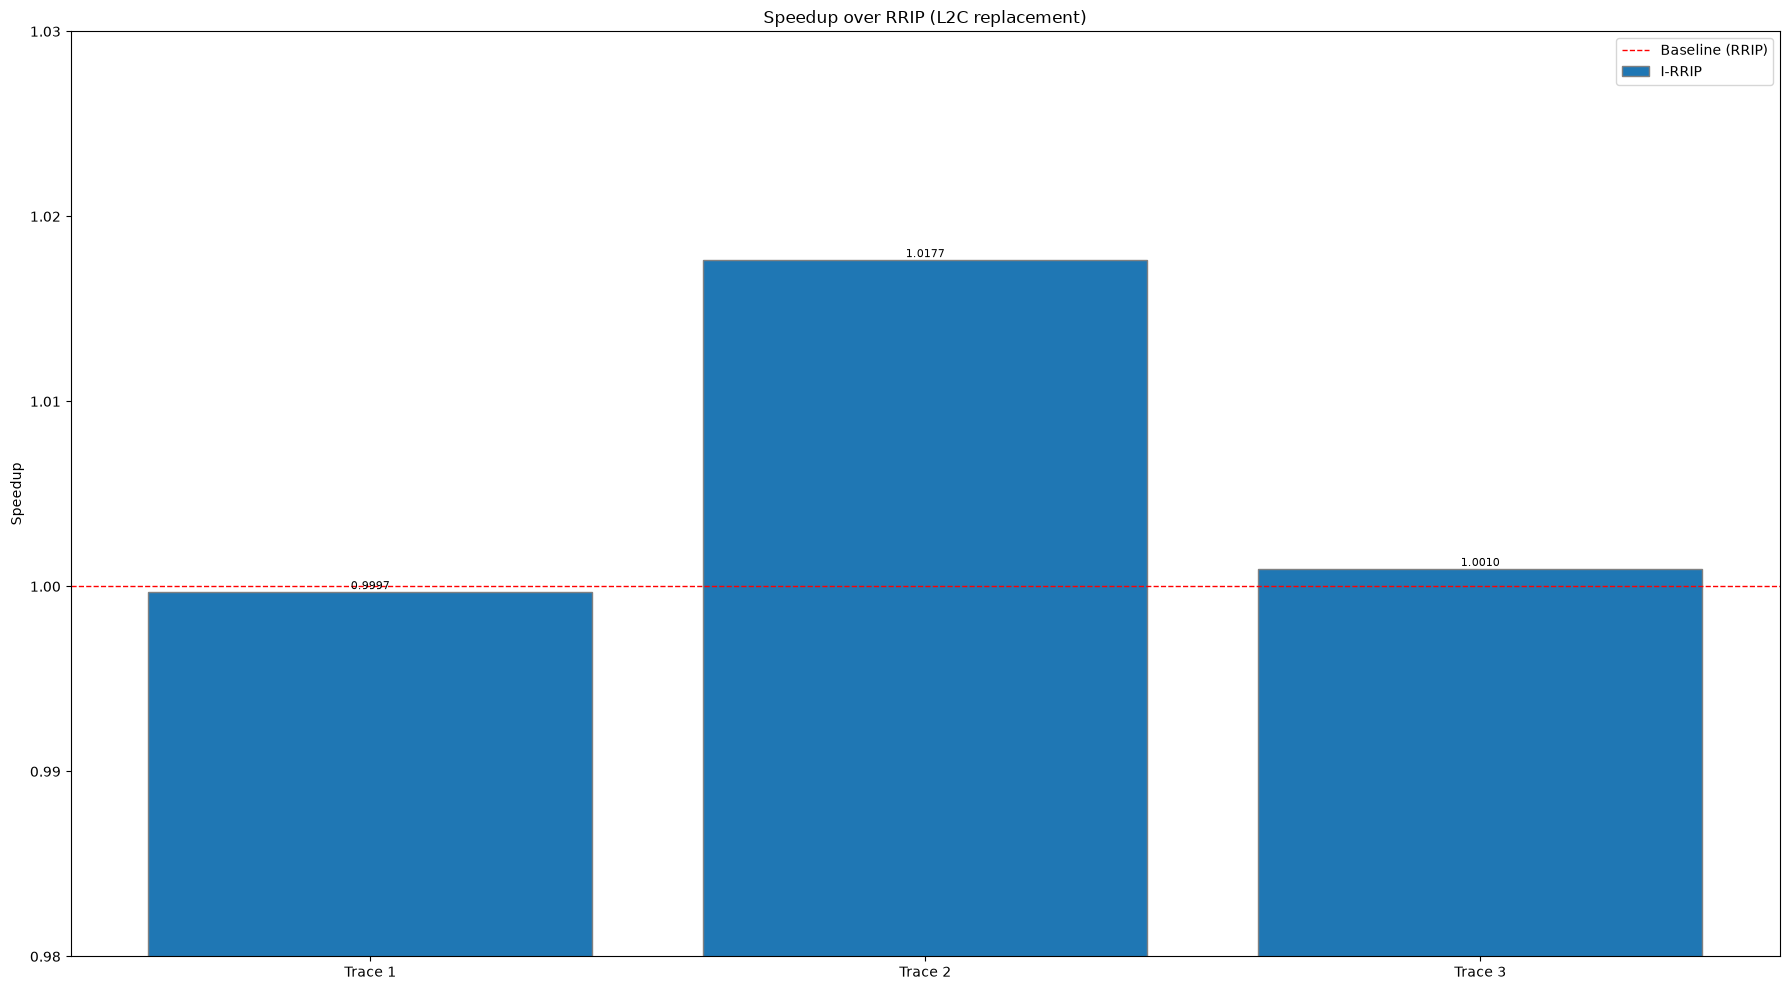

In [7]:
# Figure 2a-1: speedup over baseline
policies = [p for p in data if p != BASELINE]
width = 0.8 / len(policies)
x = range(len(traces))

fig, ax = plt.subplots(figsize=(18, 10))
for k, p in enumerate(policies):
    sp = [data[p]["ipc"][i] / data[BASELINE]["ipc"][i] for i in x]
    pos = [i + (k - (len(policies) - 1) / 2) * width for i in x]
    bars = ax.bar(pos, sp, width, label=p, edgecolor="gray")
    for b, v in zip(bars, sp):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
ax.axhline(1.0, color="red", linestyle="--", linewidth=1, label=f"Baseline ({BASELINE})")
ax.set_xticks(list(x))
ax.set_xticklabels(traces)
ax.set_ylabel("Speedup")
ax.set_title(f"Speedup over {BASELINE} (L2C replacement)")
lo = min(0.98, min(data[p]["ipc"][i] / data[BASELINE]["ipc"][i] for p in policies for i in x) - 0.005)
hi = max(1.03, max(data[p]["ipc"][i] / data[BASELINE]["ipc"][i] for p in policies for i in x) + 0.01)
ax.set_ylim(lo, hi)
ax.legend()
fig.tight_layout()
fig.savefig("figures/task2a_speedup.png", dpi=400)
plt.show()

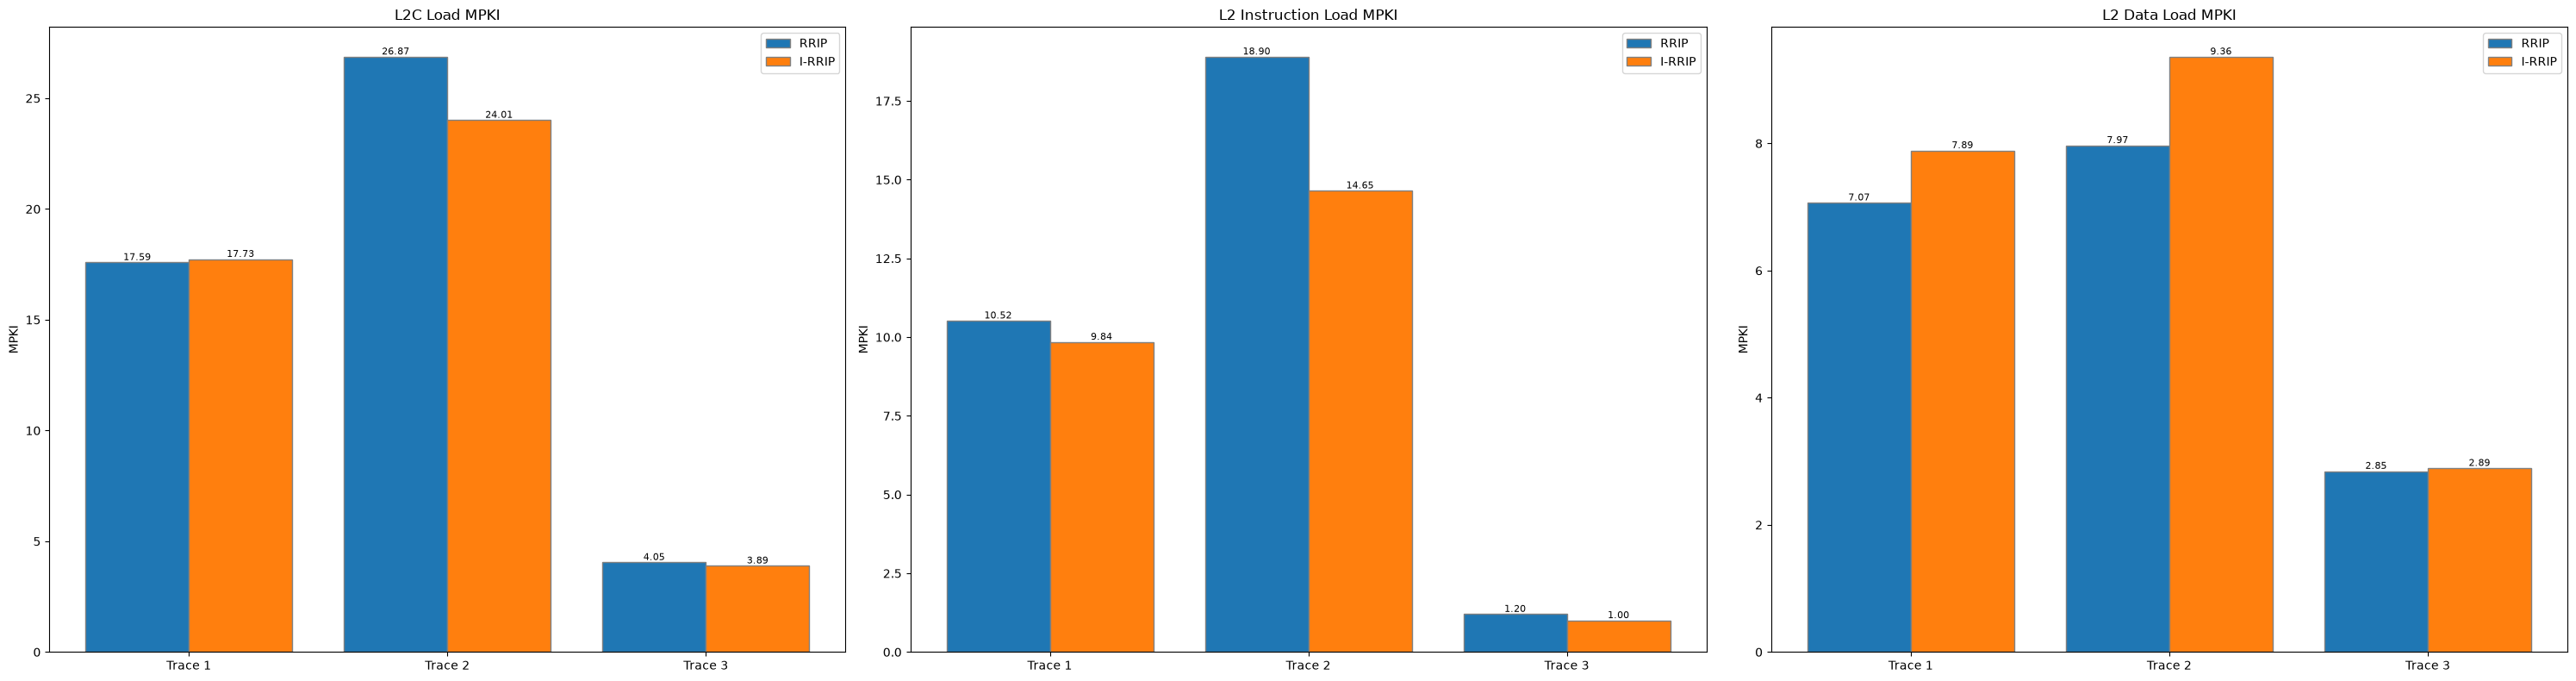

In [8]:
# Figure 2a-2: L2C load MPKI (total, instruction, data)
metrics = [("l2c_load", "L2C Load MPKI"),
           ("l2c_instr", "L2 Instruction Load MPKI"),
           ("l2c_data", "L2 Data Load MPKI")]
all_policies = list(data.keys())
width = 0.8 / len(all_policies)
x = range(len(traces))

fig, axes = plt.subplots(1, 3, figsize=(30, 8))
for ax, (key, title) in zip(axes, metrics):
    for k, p in enumerate(all_policies):
        pos = [i + (k - (len(all_policies) - 1) / 2) * width for i in x]
        bars = ax.bar(pos, data[p][key], width, label=p, edgecolor="gray")
        for b, v in zip(bars, data[p][key]):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(list(x))
    ax.set_xticklabels(traces)
    ax.set_ylabel("MPKI")
    ax.set_title(title)
    ax.legend()
fig.tight_layout()
fig.savefig("figures/task2a_mpki.png", dpi=400)
plt.show()

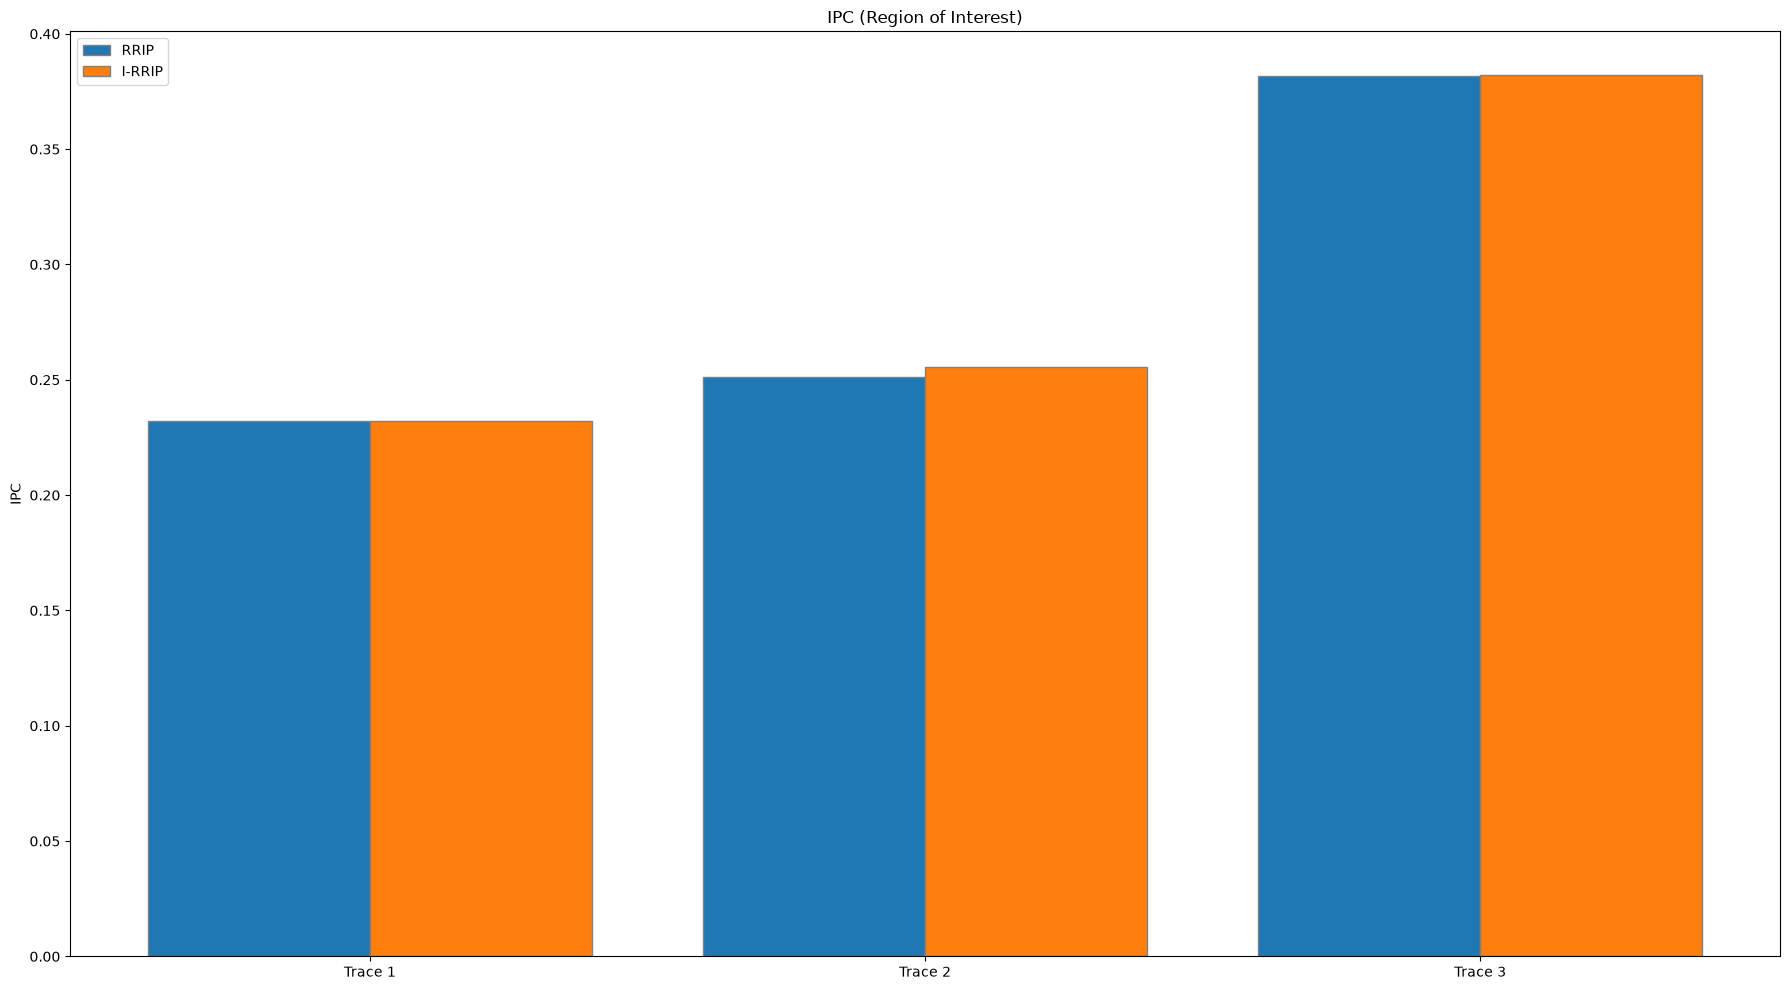

In [9]:
# Optional: IPC bars (absolute), if you also want to show raw IPC
fig, ax = plt.subplots(figsize=(18, 10))
width = 0.8 / len(all_policies)
for k, p in enumerate(all_policies):
    pos = [i + (k - (len(all_policies) - 1) / 2) * width for i in range(len(traces))]
    ax.bar(pos, data[p]["ipc"], width, label=p, edgecolor="gray")
ax.set_xticks(range(len(traces)))
ax.set_xticklabels(traces)
ax.set_ylabel("IPC")
ax.set_title("IPC (Region of Interest)")
ax.legend()
fig.tight_layout()
fig.savefig("figures/task2a_ipc.png", dpi=400)
plt.show()